<script src="/course_model/toc.js"></script>

# K-Means Clustering

K-Means is a popular unsupervised machine learning algorithm used for *clustering* tasks. The algorithm works by partitioning the data into K distinct clusters based on feature similarity. There is no target variable in clustering, as the goal is to group similar data points together rather than predict a specific outcome.

**Outcomes**:
- Understand the K-Means clustering algorithm
- Differentiate between supervised and unsupervised learning (i.e., dependent variable)
- Explain why K-Means does not use test/train splits 
- Explain why K-means needs scaling
- Learn how to choose the number of clusters (K) with an elbow plot
- Interpret clustering results

**Links**:
- State characteristics [template](template.ipynb) and [datafile](statelife.csv)
- Alternative datafile of [states](StateDemographics2.xlsx)
- Morgantown real estate [datafile](zillowmorgantown_latlong.csv)
- [K-Means Lab](kmeans.html): in-class simulation

## Roadmap

Use this map to follow the code blocks below. Steps 4a and 4b both happen in the Step 4 code block.

![K-Means roadmap](kmeans-roadmap.svg)

## Algorithm Overview

K-Means is an *unsupervised learning* algorithm, meaning it does not use labeled data for training. It identifies patterns and structures in the data based on feature similarity.

The algorithm works by initializing K centroids (the center points of the clusters) and then repeating two steps:

1. Assignment step: place each data point in the cluster of its nearest centroid.
2. Update step: move each centroid to the average of the points now assigned to it.

These steps repeat until the assignments stop changing. Because the result depends on where the centroids start, K-Means is usually run several times with different random starting centroids, keeping the best result.

Key Concepts:
- We do not use data splitting (train/test), as there is no *dependent variable*. 
- When teaching, we will sometimes compare the clusters against an outcome variable to see how well the clusters align. However, this is not likely to be done with real-world problems, where you want to find natural groupings.


Problems:
- K-Means assumes that clusters are spherical and equally sized, which may not always be the case in real-world data.
- Choosing K is a subjective process.
    - The elbow method is a common technique to help choose K by plotting the inertia (within-cluster sum of squares) as a function of K and looking for an "elbow" point where the rate of decrease sharply changes
    - However, there is no definitive way to choose K, and it may require domain knowledge or experimentation.
- Scaling features
    - Feature scaling is important for distance-based algorithms like K-Means
    - Otherwise, features with larger scales can dominate the distance calculations (for example, age in years vs. income in thousands of dollars)
    - Scaling can be done using techniques like Min-Max scaling (values run from 0 to 1) or Z-score standardization (mean of 0 and standard deviation of 1).

Interpretation:
- Overall model:
    - No accuracy measures! There is no dependent variable (except when teaching).
    - We can visualize the clusters using scatter plots or other dimensionality reduction techniques (e.g., PCA) to see how well the clusters are separated.
    - We can evaluate the clustering quality using inertia (sum of squared distances to nearest centroid).
        - Lower inertia means tighter clusters, but only compare inertia between models with the same K. Inertia always falls as K increases, so a lower value from a larger K does not mean better clusters.
    - The silhouette score compares how close each point is to its own cluster versus the nearest other cluster.
        - It ranges from -1 to 1. Values near 1 mean well-separated clusters, values near 0 mean overlapping clusters, and negative values mean points may be in the wrong cluster.
        - Unlike inertia, it can be compared across different values of K.
- Individual predictions:
    - Each row is given a cluster label. The numbers are arbitrary: cluster 0 is not "first" or "best" in any sense.
    - To describe what a cluster represents, look at its center or the average feature values of its rows.

### Step 1: Load and Explore the Data

In [1]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Create a DataFrame for easier manipulation
df = pd.DataFrame(X, columns=iris.feature_names)
df['species'] = iris.target_names[y]

df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


### Step 2: Standardize the Features

Standardization is crucial for K-Means because the algorithm is distance-based. Features with larger scales will dominate the distance calculations.

In [2]:
# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original data - first sample:")
print(X[0])
print("\nStandardized data - first sample:")
print(X_scaled[0])
print("\nMean of standardized features (should be ~0):")
print(X_scaled.mean(axis=0))
print("\nStd of standardized features (should be ~1):")
print(X_scaled.std(axis=0))

Original data - first sample:
[5.1 3.5 1.4 0.2]

Standardized data - first sample:
[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]

Mean of standardized features (should be ~0):
[-1.69031455e-15 -1.84297022e-15 -1.69864123e-15 -1.40924309e-15]

Std of standardized features (should be ~1):
[1. 1. 1. 1.]


### Step 3: Find Optimal Number of Clusters (Elbow Method)

The Elbow Method helps determine the optimal number of clusters (K) by plotting the inertia (within-cluster sum of squares) against different K values.

The inertia is the *sum of squared distances* between each *point* and its assigned *cluster center*. As K increases, inertia decreases because points are closer to their cluster centers. The goal is to find the "elbow" point where the rate of decrease sharply changes, indicating a suitable K.

In the plot below, inertia drops sharply from K=1 (600) to K=2 (about 222), drops again at K=3 (about 140), and then flattens out. Either 2 or 3 is a defensible elbow. We use 3 here, but in a real problem you would weigh that choice using domain knowledge.

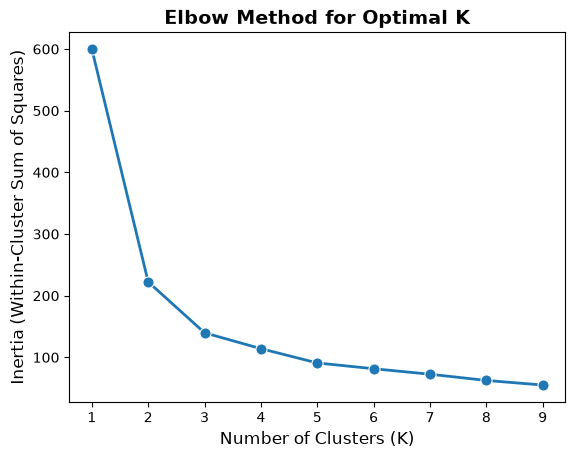

In [3]:
# Plot inertia for different numbers of clusters
import seaborn as sns
import matplotlib.pyplot as plt

inertias = []
range_tested = range(1, 10)

for k in range_tested:
    # K-Means clustering function uses a given number of clusters, a random seed (random_state) for reproducibility, 
    # and n_init for stability (number of initializations, meaning the algorithm will run multiple times 
    # with different centroid seeds)
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

# Plot the elbow curve as a single plot
sns.lineplot(x=range_tested, y=inertias, marker='o', linewidth=2, markersize=8)
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
plt.title('Elbow Method for Optimal K', fontsize=14, fontweight='bold')
plt.show()

### Step 4: Build and Fit the K-Means Model

We also print the silhouette score. A value of about 0.46 means the clusters are reasonably separated, but with some overlap.

In [4]:
# Create and fit K-Means model with 3 clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to the dataframe
df['cluster'] = cluster_labels

print("Cluster Centers (standardized):")
print(kmeans.cluster_centers_)
print("\nCluster Distribution:")
print(df['cluster'].value_counts().sort_index())
print("\nSilhouette Score:", silhouette_score(X_scaled, cluster_labels))

Cluster Centers (standardized):
[[-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]
 [ 1.13597027  0.08842168  0.99615451  1.01752612]]

Cluster Distribution:
cluster
0    53
1    50
2    47
Name: count, dtype: int64

Silhouette Score: 0.45994823920518635


### Step 5: Visualize the Clusters

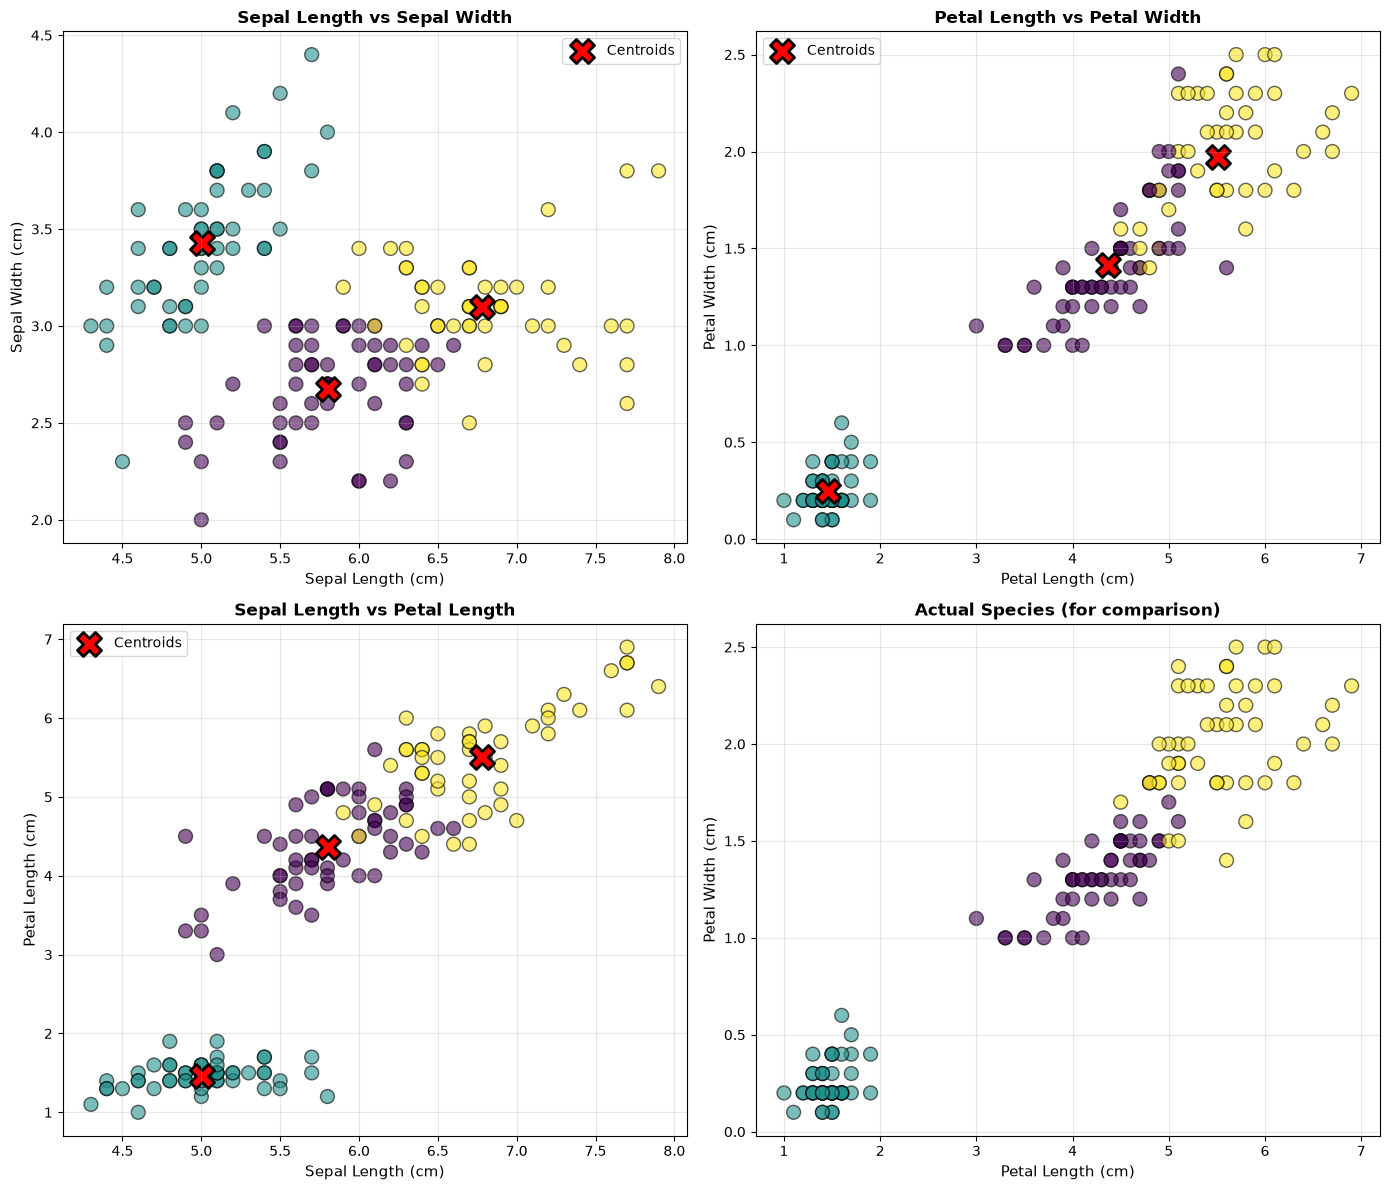

In [5]:
# Create scatter plots for different feature combinations
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Plot 1: Sepal Length vs Sepal Width
ax = axes[0, 0]
scatter1 = ax.scatter(df['sepal length (cm)'], df['sepal width (cm)'], 
                      c=df['cluster'], cmap='viridis', s=100, alpha=0.6, edgecolors='black')
ax.scatter(scaler.inverse_transform(kmeans.cluster_centers_)[:, 0],
           scaler.inverse_transform(kmeans.cluster_centers_)[:, 1],
           c='red', marker='X', s=300, edgecolors='black', linewidths=2, label='Centroids')
ax.set_xlabel('Sepal Length (cm)', fontsize=11)
ax.set_ylabel('Sepal Width (cm)', fontsize=11)
ax.set_title('Sepal Length vs Sepal Width', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 2: Petal Length vs Petal Width
ax = axes[0, 1]
scatter2 = ax.scatter(df['petal length (cm)'], df['petal width (cm)'], 
                      c=df['cluster'], cmap='viridis', s=100, alpha=0.6, edgecolors='black')
ax.scatter(scaler.inverse_transform(kmeans.cluster_centers_)[:, 2],
           scaler.inverse_transform(kmeans.cluster_centers_)[:, 3],
           c='red', marker='X', s=300, edgecolors='black', linewidths=2, label='Centroids')
ax.set_xlabel('Petal Length (cm)', fontsize=11)
ax.set_ylabel('Petal Width (cm)', fontsize=11)
ax.set_title('Petal Length vs Petal Width', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 3: Sepal Length vs Petal Length
ax = axes[1, 0]
scatter3 = ax.scatter(df['sepal length (cm)'], df['petal length (cm)'], 
                      c=df['cluster'], cmap='viridis', s=100, alpha=0.6, edgecolors='black')
ax.scatter(scaler.inverse_transform(kmeans.cluster_centers_)[:, 0],
           scaler.inverse_transform(kmeans.cluster_centers_)[:, 2],
           c='red', marker='X', s=300, edgecolors='black', linewidths=2, label='Centroids')
ax.set_xlabel('Sepal Length (cm)', fontsize=11)
ax.set_ylabel('Petal Length (cm)', fontsize=11)
ax.set_title('Sepal Length vs Petal Length', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot 4: Comparison with actual species
ax = axes[1, 1]
# Cluster numbers are arbitrary, so give each species the number of the cluster it
# mostly landed in. That way the colors here match the colors in the other three plots.
species_colors = pd.crosstab(df['species'], df['cluster']).idxmax(axis=1)
scatter4 = ax.scatter(df['petal length (cm)'], df['petal width (cm)'], 
                      c=df['species'].map(species_colors), cmap='viridis', 
                      s=100, alpha=0.6, edgecolors='black')
ax.set_xlabel('Petal Length (cm)', fontsize=11)
ax.set_ylabel('Petal Width (cm)', fontsize=11)
ax.set_title('Actual Species (for comparison)', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Step 6: Compare Clusters to Known Species (teaching only)

Since we have the actual species labels, we can compare our clusters with the true labels. This is only possible because iris is a teaching dataset; a real clustering problem has no known answer to check against.

Cluster numbers are arbitrary, so cluster 0 does not have to line up with the first species. Instead, we look at which species makes up most of each cluster. Cluster purity is the share of a cluster made up of its most common species.

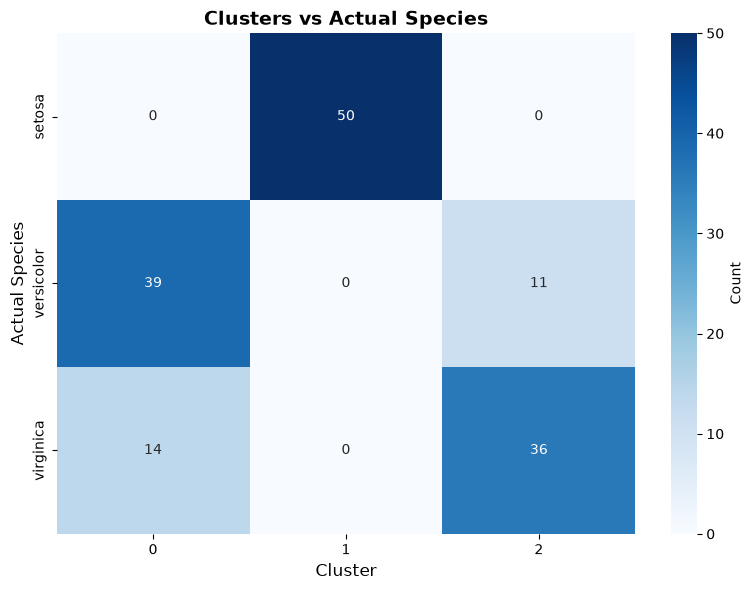

Cluster composition by species:
cluster      0   1   2
species               
setosa       0  50   0
versicolor  39   0  11
virginica   14   0  36

Analysis:
Cluster 0: Mainly versicolor (73.6% purity)
Cluster 1: Mainly setosa (100.0% purity)
Cluster 2: Mainly virginica (76.6% purity)


In [6]:
# Count how many flowers of each species landed in each cluster
cluster_species = pd.crosstab(df['species'], df['cluster'])

# Plot the counts. Cluster numbers are arbitrary, so the diagonal has no special meaning.
plt.figure(figsize=(8, 6))
sns.heatmap(cluster_species, annot=True, fmt='d', cmap='Blues', cbar_kws={'label': 'Count'})
plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Actual Species', fontsize=12)
plt.title('Clusters vs Actual Species', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Calculate cluster purity
print("Cluster composition by species:")
print(cluster_species)
print("\n" + "="*50)
print("Analysis:")
print("="*50)
for cluster in range(3):
    dominant_species = cluster_species[cluster].idxmax()
    purity = cluster_species[cluster].max() / cluster_species[cluster].sum()
    print(f"Cluster {cluster}: Mainly {dominant_species} ({purity:.1%} purity)")

## Key Terms

- **K-Means**: An unsupervised algorithm that partitions the data into K clusters based on feature similarity
- **Clustering**: Grouping similar data points together rather than predicting a specific outcome
- **Unsupervised learning**: Learning from data that has no labeled outcome, finding patterns and structure from the features alone
- **Supervised learning**: Learning from data that has a known outcome (dependent variable) to predict, as in regression or decision trees
- **Cluster**: A group of data points that are more similar to each other than to points in other groups
- **Centroid**: The center point of a cluster, located at the average of the points assigned to it
- **K**: The number of clusters, chosen by the analyst before the algorithm runs (`n_clusters`)
- **Inertia**: The sum of squared distances between each point and its assigned cluster center; also called the within-cluster sum of squares
- **Elbow method**: Plotting inertia against different values of K to help choose the number of clusters
- **Distance-based algorithm**: An algorithm that relies on how far apart points are, so features with larger scales can dominate
- **Feature scaling**: Putting all features on a comparable scale so that no single feature dominates the distance calculations
- **Z-score standardization**: Rescaling a feature to a mean of 0 and a standard deviation of 1 (`StandardScaler`)
- **Min-Max scaling**: Rescaling a feature so its values run from 0 to 1
- **Spherical cluster assumption**: The K-Means assumption that clusters are round and roughly equal in size
- **Cluster purity**: The share of a cluster made up of its most common known category; only available when true labels exist


## Practice Questions

1. What kind of machine learning is K-Means?
   - Unsupervised learning used for clustering
   - Supervised learning used for classification
   - Supervised learning used for regression
   - A method for filling in missing values
1. What is the main difference between supervised and unsupervised learning?
   - Supervised learning has a dependent variable to predict; unsupervised learning does not
   - Supervised learning needs scaled features; unsupervised learning does not
   - Supervised learning only uses numeric data; unsupervised learning only uses text
   - Supervised learning needs more rows than unsupervised learning
1. What is the goal of clustering?
   - To group similar data points together
   - To predict a specific outcome for each row
   - To test whether a coefficient is significant
   - To remove outliers from the data
1. What does the K in K-Means stand for?
   - The number of clusters
   - The number of features
   - The number of rows
   - The number of times the algorithm runs
1. What is a centroid?
   - The center point of a cluster
   - The point farthest from the rest of the cluster
   - The first row in the dataset
   - The feature with the largest scale
1. How does the K-Means algorithm work?
   - It assigns each point to the nearest centroid, updates the centroids, and repeats
   - It splits the data with a series of yes/no rules
   - It fits a line that minimizes the squared residuals
   - It sorts the rows and cuts them into K equal groups
1. Why does K-Means not use a train/test split?
   - There is no dependent variable to check predictions against
   - K-Means only works on very small datasets
   - Splitting the data would change the scale of the features
   - K-Means cannot overfit
1. Why do we scale features before running K-Means?
   - It is distance-based, so features with larger scales would dominate the distance calculations
   - K-Means cannot read numbers larger than 1
   - Scaling removes rows with missing values
   - Scaling chooses the number of clusters automatically
1. A dataset has age in years and income in dollars. What happens if you run K-Means without scaling?
   - Income dominates the distances, so the clusters are driven almost entirely by income
   - Age dominates because it has smaller numbers
   - Both features contribute equally
   - The algorithm fails with an error
1. After using `StandardScaler`, what are the mean and standard deviation of each feature?
   - A mean of about 0 and a standard deviation of 1
   - A mean of 1 and a standard deviation of 0
   - A minimum of 0 and a maximum of 1
   - The same as before scaling
1. A feature has a mean of 50 and a standard deviation of 10. What is the standardized value of 70?
   - 2, because (70 - 50) / 10
   - 20
   - 7
   - 0.7
1. What is inertia?
   - The sum of squared distances between each point and its assigned cluster center
   - The number of points in the largest cluster
   - The distance between the two closest centroids
   - The share of points placed in the correct cluster
1. A cluster has three points that are 1, 2, and 2 units away from its centroid. What is the inertia for this cluster?
   - 9, because 1 + 4 + 4
   - 5, because 1 + 2 + 2
   - 3
   - 25
1. What happens to inertia as K increases?
   - It decreases, because points are closer to their cluster centers
   - It increases, because there are more clusters to measure
   - It stays the same
   - It becomes negative
1. Why not simply choose the K with the lowest inertia?
   - Inertia keeps falling as K rises, so the lowest inertia would put every point in its own cluster
   - A lower inertia means the clusters are worse
   - Inertia can only be calculated for K = 3
   - The lowest inertia always occurs at K = 1
1. On an elbow plot, which K do you look for?
   - The point where the rate of decrease in inertia sharply changes
   - The largest K tested
   - The K where inertia reaches zero
   - The K with the highest inertia
1. Which statement about choosing K is true?
   - It is subjective and may require domain knowledge or experimentation
   - The elbow method always gives a single correct answer
   - K must equal the number of features
   - K is chosen automatically by `StandardScaler`
1. What does K-Means assume about the shape of clusters?
   - They are spherical and roughly equal in size
   - They are long and thin
   - They always overlap
   - They contain exactly the same number of points
1. What does `n_init=10` do in `KMeans(n_clusters=3, random_state=42, n_init=10)`?
   - Runs the algorithm 10 times with different starting centroids and keeps the best result
   - Creates 10 clusters
   - Limits the algorithm to 10 rows
   - Tests values of K from 1 to 10
1. In the iris example, we compare clusters to the actual species. Why is this not usually done with real-world clustering problems?
   - Real-world clustering problems have no known outcome; the aim is to find natural groupings
   - The comparison only works with exactly three clusters
   - A confusion matrix cannot be built from cluster labels
   - Species labels are needed to run K-Means
1. Does cluster number 0 have to match the first species in the dataset?
   - No, cluster numbers are arbitrary labels; in our results cluster 1 is the one that is all setosa
   - Yes, clusters are numbered in the same order as the species
   - Yes, but only when the features are scaled
   - No, because cluster 0 is always the largest cluster